# Enhanced Exploratory Data Analysis

This notebook analyzes the official test set and synthetic train/dev/test splits. Official-test annotations are used only for descriptive evaluation and reporting.

In [1]:
import json
from collections import Counter
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
SYNTHETIC = ROOT / "data" / "synthetic"
PII_TYPES = ["ОСОБА", "АДРЕСА", "НОМЕР", "ІНФОРМАЦІЯ"]
SPLITS = ["train", "dev", "test_a", "test_b"]

def load_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


## 1. Split and PII summary

In [2]:
summary = []
records = {}
for split in SPLITS:
    rows = load_jsonl(SYNTHETIC / f"{split}.jsonl")
    records[split] = rows
    anns = [a for r in rows for a in r["annotations"]]
    types = Counter(a["pseudonym"].split("_", 1)[0] for a in anns)
    persons = [a for a in anns if a["pseudonym"].startswith("ОСОБА_")]
    summary.append({
        "split": split,
        "documents": len(rows),
        "annotations": len(anns),
        "annotations_per_document": round(len(anns) / len(rows), 2),
        "median_document_length": int(pd.Series([len(r["original"]) for r in rows]).median()),
        "ОСОБА": types["ОСОБА"],
        "АДРЕСА": types["АДРЕСА"],
        "НОМЕР": types["НОМЕР"],
        "ІНФОРМАЦІЯ": types["ІНФОРМАЦІЯ"],
        "uncertain_cases": sum(a.get("case_confident") is False for a in persons),
        "random_gender": sum(a.get("gender_from_context") is False for a in persons),
        "clear_text_names": sum(a.get("subtype") == "clear_name" for a in anns),
    })
summary_df = pd.DataFrame(summary)
summary_df

,split,documents,annotations,annotations_per_document,median_document_length,ОСОБА,АДРЕСА,НОМЕР,ІНФОРМАЦІЯ,uncertain_cases,random_gender,clear_text_names
0,train,4895,103482,21.14,5536,76203,6627,10324,10328,14486,13058,12395
1,dev,300,6258,20.86,5416,5187,412,456,203,1423,1479,1081
2,test_a,526,9649,18.34,5135,8139,471,589,450,1396,1452,1835
3,test_b,377,14505,38.47,8892,7987,1124,2426,2968,1865,1371,699


## 2. PII composition by split

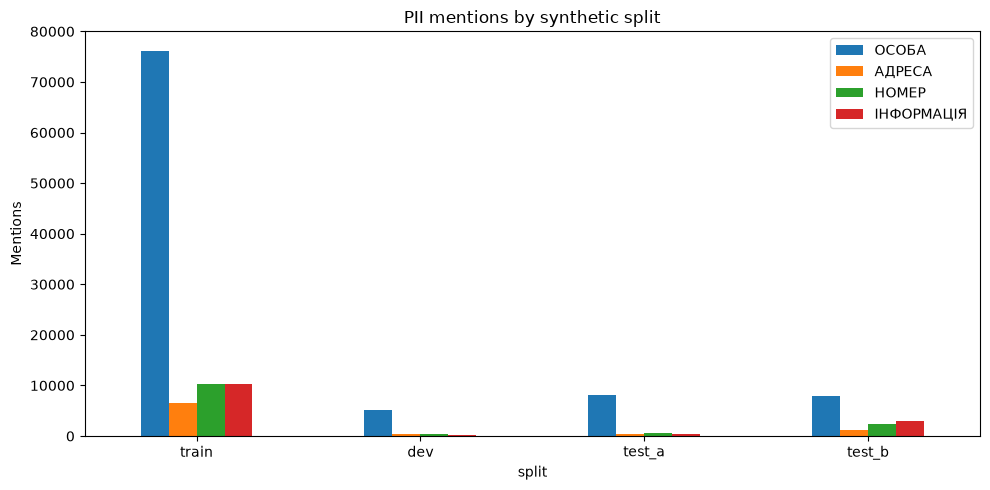

In [3]:
plot_df = summary_df.set_index("split")[PII_TYPES]
ax = plot_df.plot(kind="bar", figsize=(10, 5), rot=0)
ax.set_title("PII mentions by synthetic split")
ax.set_ylabel("Mentions")
plt.tight_layout()


## 3. Document length and annotations

In [4]:
length_stats = []
for split, rows in records.items():
    lengths = pd.Series([len(r["original"]) for r in rows])
    length_stats.append({
        "split": split,
        "mean": round(lengths.mean(), 1),
        "median": int(lengths.median()),
        "q25": int(lengths.quantile(.25)),
        "q75": int(lengths.quantile(.75)),
        "max": int(lengths.max()),
    })
pd.DataFrame(length_stats)

,split,mean,median,q25,q75,max
0,train,7144.3,5536,3165,10136,26204
1,dev,6921.6,5416,3173,9327,21622
2,test_a,7070.8,5135,3058,10082,22109
3,test_b,9408.9,8892,4492,13092,21515


## 4. Person case and gender quality

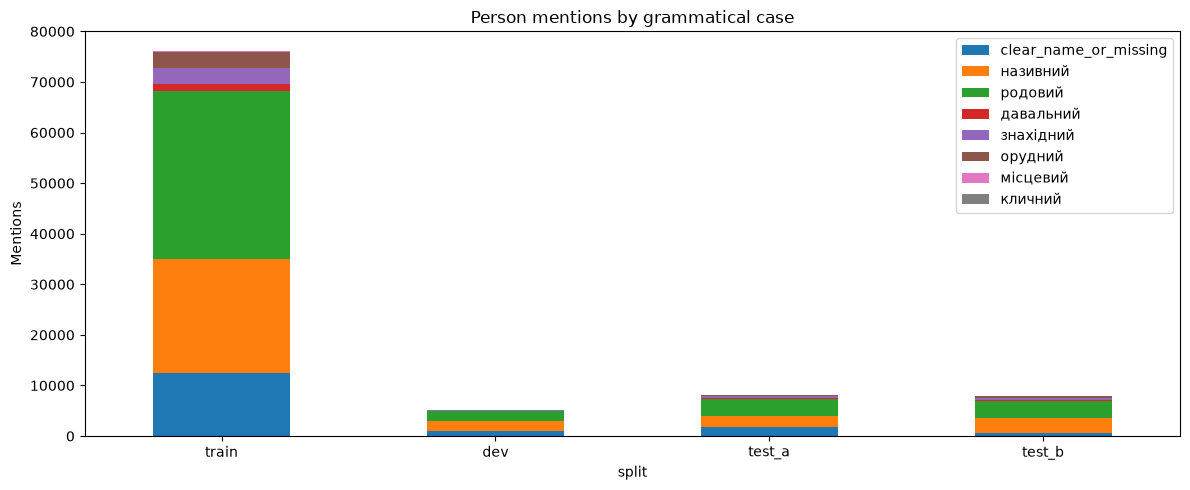

In [5]:
case_rows = []
for split, rows in records.items():
    persons = [a for r in rows for a in r["annotations"] if a["pseudonym"].startswith("ОСОБА_")]
    cases = Counter(a.get("case") or "clear_name_or_missing" for a in persons)
    case_rows.append({"split": split, **dict(cases)})
case_df = pd.DataFrame(case_rows).fillna(0).set_index("split")
ax = case_df.plot(kind="bar", stacked=True, figsize=(12, 5), rot=0)
ax.set_title("Person mentions by grammatical case")
ax.set_ylabel("Mentions")
plt.tight_layout()


## 5. PII subtypes

In [6]:
subtype_rows = []
for split, rows in records.items():
    counts = Counter(a.get("subtype", "missing") for r in rows for a in r["annotations"] if a.get("subtype"))
    subtype_rows.append({"split": split, **dict(counts)})
subtype_df = pd.DataFrame(subtype_rows).fillna(0).set_index("split")
subtype_df.T


split,train,dev,test_a,test_b
clear_name,12395.0,1081.0,1835.0,699.0
email,267.0,8.0,4.0,109.0
ipn,1793.0,70.0,148.0,251.0
birth_date,3755.0,107.0,262.0,546.0
other,6118.0,193.0,285.0,1958.0
iban,630.0,4.0,12.0,292.0
military_unit,950.0,120.0,153.0,47.0
phone,632.0,19.0,22.0,205.0
passport,290.0,2.0,1.0,98.0
unit_or_institution,2827.0,7.0,6.0,1186.0


## 6. Rare-subtype coverage

In [7]:
rare = subtype_df.loc[["test_b", "train"]].T
rare[rare.max(axis=1) >= 50].sort_values("test_b", ascending=False).head(20)


split,test_b,train
other,1958.0,6118.0
unit_or_institution,1186.0,2827.0
clear_name,699.0,12395.0
birth_date,546.0,3755.0
iban,292.0,630.0
plate,256.0,1696.0
ipn,251.0,1793.0
phone,205.0,632.0
death_date,147.0,898.0
url,126.0,25.0


## 7. Official-test distribution

In [8]:
official = load_jsonl(ROOT / "data" / "test" / "court_cases.jsonl")
official_anns = [a for r in official for a in r["annotations"]]
official_types = Counter(a["pseudonym"].split("_", 1)[0].strip() for a in official_anns)
pd.DataFrame({"PII type": PII_TYPES, "mentions": [official_types[t] for t in PII_TYPES]})


,PII type,mentions
0,ОСОБА,2837
1,АДРЕСА,233
2,НОМЕР,447
3,ІНФОРМАЦІЯ,168


## 8. Domain shift

In [9]:
domain_df = pd.DataFrame([
    {"dataset": "synthetic_train", "documents": 4895, "median_chars": summary_df.loc[summary_df.split == "train", "median_document_length"].iloc[0]},
    {"dataset": "synthetic_dev", "documents": 300, "median_chars": summary_df.loc[summary_df.split == "dev", "median_document_length"].iloc[0]},
    {"dataset": "official_test", "documents": len(official), "median_chars": int(pd.Series([len(r["original"]) for r in official]).median())},
])
domain_df


,dataset,documents,median_chars
0,synthetic_train,4895,5536
1,synthetic_dev,300,5416
2,official_test,240,5833


## 9. Findings

- Synthetic test_b is intentionally enriched for rare subtypes.
- Official test is a separate domain and must not be used for model selection or tuning.
- Person-case confidence and gender-from-context flags identify likely quality weak points.
- Clear-text names are additional person annotations and require a separate error analysis.
- Address-region consistency, linked person identifiers, and informal-language coverage remain to be measured.